# Notebook 3. Evaluación



Objetivo: antes de mejorar el RAG, saber medirlo. Medimos la recuperación con verdad de referencia por página
(recall@k y MRR@k escritos a mano) y la respuesta con un LLM-as-a-judge (la tríada del RAG). Al final, V0 y V1
quedan en `results.csv`, la tabla que irán llenando los notebooks siguientes.

Lo más avanzado (nDCG, calibrar el judge con etiquetas humanas y la kappa de Cohen, y el contraste con la
librería ranx) está en `anexos/A3_evaluacion_avanzada.ipynb`.

Referencias:
- LLM-as-a-judge con MT-Bench y Chatbot Arena: https://arxiv.org/abs/2306.05685
- Ragas (fidelidad, relevancia de la respuesta y del contexto): https://arxiv.org/abs/2309.15217
- Survey de RAG (sección de evaluación): https://arxiv.org/abs/2312.10997

In [8]:
import torch
from rag_lab import CFG, models, set_seeds, summary

# CFG.FAST_MODE = False  # corpus de control completo (por defecto se lee FAST_MODE de .env)
# CFG.DOC_PATH = CFG.DATA_DIR / "mi_documento.pdf"  # cualquier PDF sirve
if not CFG.FORCE_CPU and torch.cuda.is_available():
    free_bytes, total_bytes = torch.cuda.mem_get_info()
    if total_bytes < 6 * 1024**3 or free_bytes < 3 * 1024**3:
        CFG.FORCE_CPU = True
        print(
            f"GPU con {total_bytes / 2**30:.1f} GiB total y {free_bytes / 2**30:.1f} GiB libres; "
            "se usará CPU para evitar falta de memoria."
        )

# Libera modelos que puedan haber quedado cargados por otros notebooks en este kernel.
models.release()
set_seeds()
summary()

Documento:   C:\Users\duque\Desktop\Nueva carpeta\data\documento.pdf (existe)
FAST_MODE:   True
Dispositivo: cpu
GEN_MODEL:   google/gemini-3.1-flash-lite
JUDGE_MODEL: openai/gpt-5-mini
VLM_MODEL:   google/gemini-3.1-flash-lite
OpenRouter:  clave configurada
Trazas:      jsonl C:\Users\duque\Desktop\Nueva carpeta\trazas\trazas.jsonl  (alumno: duque)


## 1. Verdad de referencia por página

Cada pregunta guarda la página de la que sale y su tipo (`texto`, `tabla`, `visual`). Un fragmento acierta si
proviene de alguna página correcta, así que la misma verdad sirve para cualquier chunking, para páginas enteras
o para figuras. Las preguntas son un borrador generado con un LLM (`revisar_manual = true`): revísalas antes de
sacar conclusiones.

In [9]:
import pandas as pd
from rag_lab import evaluation

questions = evaluation.load_questions()
df_questions = pd.DataFrame(questions)
print(df_questions["tipo"].value_counts().to_dict(), "| pendientes de revisar:", int(df_questions["revisar_manual"].sum()))
df_questions[["id", "tipo", "paginas", "tabla_gemela", "pregunta"]]

{'texto': 7, 'tabla': 7, 'visual': 6} | pendientes de revisar: 20


,id,tipo,paginas,tabla_gemela,pregunta
0,q01,texto,[2],NaN,¿Qué línea se centra en la promoción del equil...
1,q02,texto,[3],NaN,Cuál es la duración total del proyecto según e...
2,q03,texto,[6],NaN,¿Cuál es el nombre del profesor del Centro de ...
3,q04,texto,[11],NaN,¿Cuántas fases principales componen el desarro...
4,q05,texto,[9],NaN,¿Qué centro de innovación y desarrollo para la...
5,q06,texto,[7],NaN,¿Cuál es la titulación del desarrollador backe...
6,q07,texto,[8],NaN,¿Cuál es el objetivo de la Tarea 9 dentro de l...
7,q08,tabla,[18],17.0,¿Qué instrumento se utiliza para medir el impa...
8,q09,tabla,[17],17.0,¿Qué instrumento se utiliza para medir el nive...
9,q10,tabla,[14],13.0,¿Cuántas empresas se beneficiarán por curso se...


## 2. recall@k y MRR@k a mano

- **recall@k** (aquí, con una página correcta, equivale a *hit rate*): 1 si alguna de las k primeras unidades
  sale de una página correcta.
- **MRR@k**: inverso de la posición de la primera unidad correcta (1, 1/2, 1/3...), 0 si no aparece en las k primeras.

In [10]:
def recall_k(retrieved, correct, k):
    return float(any(set(u) & set(correct) for u in retrieved[:k]))

def mrr_k(retrieved, correct, k):
    for position, unit in enumerate(retrieved[:k], start=1):
        if set(unit) & set(correct):
            return 1 / position
    return 0.0

example = [[3], [7, 8], [12], [13]]  # páginas de los fragmentos recuperados, en orden
print(recall_k(example, [12], 2), recall_k(example, [12], 5), mrr_k(example, [12], 10), mrr_k(example, [8], 10))
assert mrr_k(example, [8], 10) == evaluation.mrr_at_k(example, [8], 10)

0.0 1.0 0.3333333333333333 0.5


Aplicamos las métricas a V0 y V1 pregunta a pregunta. `evaluate_rag` ejecuta `answer` con cada pregunta, guarda
las páginas de las 10 unidades recuperadas, pasa el judge (sección 3) y añade una fila a `results.csv`.
Las llamadas al LLM están en caché, así que la celda tarda unos segundos.

In [11]:
%pip install chromadb
%pip install pymupdf

from rag_lab import results, versions
import subprocess
import sys
import importlib

try:
    import docling_core  # noqa: F401
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "docling-core"])
    importlib.invalidate_caches()

v0, v1 = versions.build("V0"), versions.build("V1")
eval_v0 = evaluation.evaluate_rag(v0, questions)
eval_v1 = evaluation.evaluate_rag(v1, questions)

def add_metrics(detail):
    pairs = list(zip(detail["recuperadas"], detail["correctas"]))
    detail["posición correcta"] = [next((i for i, u in enumerate(r, 1) if set(u) & set(c)), None) for r, c in pairs]
    detail["recall@5"] = [recall_k(r, c, 5) for r, c in pairs]
    detail["MRR@10"] = [mrr_k(r, c, 10) for r, c in pairs]
    return detail

d0, d1 = add_metrics(eval_v0["detalle"]), add_metrics(eval_v1["detalle"])
d1[["id", "tipo", "correctas", "posición correcta", "recall@5", "MRR@10"]]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


,id,tipo,correctas,posición correcta,recall@5,MRR@10
0,q01,texto,[2],2,1.0,0.500000
1,q02,texto,[3],2,1.0,0.500000
2,q03,texto,[6],1,1.0,1.000000
3,q04,texto,[11],1,1.0,1.000000
4,q05,texto,[9],1,1.0,1.000000
5,q06,texto,[7],1,1.0,1.000000
6,q07,texto,[8],1,1.0,1.000000
7,q08,tabla,[18],1,1.0,1.000000
8,q09,tabla,[17],1,1.0,1.000000
9,q10,tabla,[14],1,1.0,1.000000


La media de cada columna es lo que `rag_lab` guarda en `results.csv`. Comprobamos que coincide:

In [12]:
pd.DataFrame({
    "V0 (a mano)": d0[["recall@5", "MRR@10"]].mean(),
    "V0 (rag_lab)": pd.Series({m: eval_v0["resumen"][m] for m in ["recall@5", "MRR@10"]}),
    "V1 (a mano)": d1[["recall@5", "MRR@10"]].mean(),
    "V1 (rag_lab)": pd.Series({m: eval_v1["resumen"][m] for m in ["recall@5", "MRR@10"]}),
}).round(3)

,V0 (a mano),V0 (rag_lab),V1 (a mano),V1 (rag_lab)
recall@5,1.000,1.000,1.000,1.000
MRR@10,0.782,0.782,0.796,0.796


## 3. LLM-as-a-judge: la tríada del RAG

Tres preguntas al judge, cada una por separado, con veredicto binario (sí/no) y un razonamiento previo:
- **fidelidad**: ¿todo lo que afirma la respuesta está en el contexto?
- **relevancia de la respuesta**: ¿contesta a la pregunta?
- **relevancia del contexto**: ¿el contexto recuperado contiene lo necesario para responder?

El judge es de otra familia que el generador (sesgo de autopreferencia). La salida se pide con JSON Schema.

In [13]:
from rag_lab import judge, llm

print("Generador:", CFG.GEN_MODEL, "| Judge:", CFG.JUDGE_MODEL, "| familias distintas:", llm.check_families())
print(judge.PROMPTS["fidelidad"][:600])
print(judge.SCHEMA)

Generador: google/gemini-3.1-flash-lite | Judge: openai/gpt-5-mini | familias distintas: True
Evalúa la FIDELIDAD de la respuesta al contexto.
Veredicto 'si' cuando todas las afirmaciones de la respuesta (cifras, fechas, nombres) aparecen en el contexto o se deducen de él directamente. También 'si' cuando la respuesta dice que el contexto no contiene la información. Veredicto 'no' si alguna afirmación no está respaldada por el contexto o lo contradice.

CONTEXTO:
{context}

RESPUESTA:
{answer}
{'type': 'object', 'properties': {'razonamiento': {'type': 'string', 'description': 'Justificación breve, antes del veredicto'}, 'veredicto': {'type': 'string', 'enum': ['si', 'no']}}, 'required': ['razonamiento', 'veredicto'], 'additionalProperties': False}


In [14]:
row = d1.iloc[0]
print("Pregunta:", row["pregunta"])
print("Respuesta:", row["respuesta"])
for criterion in judge.CRITERIA:
    verdict, reason, r = judge.judge_criterion(criterion, row["pregunta"], row["respuesta"], row["contexto"])
    print(f"- {criterion}: {verdict}  ({reason[:200]})  [{r.tokens} tokens, {r.cost_usd:.5f} USD]")

Pregunta: ¿Qué línea se centra en la promoción del equilibrio de género en el acceso de la mujer a titulaciones STEAM?
Respuesta: La línea que se centra en la promoción del equilibrio de género en el acceso de la mujer a las titulaciones STEAM es la Línea 3 [p. 2].
- fidelidad: 1  (El contexto (Fragmento 2, páginas 1-2) identifica explícitamente la 'Línea 3' como la que promueve el equilibrio de género en el acceso de la mujer a titulaciones/formación STEAM, por lo que la afirma)  [2251 tokens, 0.00088 USD]
- relevancia_respuesta: 1  (La respuesta indica explícitamente qué línea se centra en esa promoción (Línea 3), por lo que responde directamente a la pregunta planteada.)  [369 tokens, 0.00033 USD]
- relevancia_contexto: 1  (El contexto incluye explícitamente la definición y descripción de la Línea 3 como la dedicada a la promoción del equilibrio de género en el acceso de la mujer a titulaciones y perfiles STEAM, con deta)  [2177 tokens, 0.00081 USD]


In [15]:
d1[["id", "tipo", "fidelidad", "relevancia_respuesta", "relevancia_contexto", "respuesta"]]

,id,tipo,fidelidad,relevancia_respuesta,relevancia_contexto,respuesta
0,q01,texto,1,1,1,La línea que se centra en la promoción del equ...
1,q02,texto,1,1,1,La duración del proyecto es de 2 años (24 mese...
2,q03,texto,1,1,1,El nombre del profesor es Mikel Díez García [p...
3,q04,texto,1,1,1,El proyecto está dividido en 5 fases principal...
4,q05,texto,1,1,1,"TKNIKA, centro de innovación y desarrollo para..."
5,q06,texto,1,1,1,Su titulación es Graduado en Ingeniería Inform...
6,q07,texto,1,1,1,El objetivo de la Tarea 9 es identificar y sel...
7,q08,tabla,1,1,1,El instrumento utilizado es el análisis de dat...
8,q09,tabla,1,1,1,El instrumento utilizado son los encuentros pe...
9,q10,tabla,1,1,1,Según el resultado esperado de capacitación en...


## 4. Resultados por versión y por tipo de pregunta

La media global esconde dónde falla cada versión. Con 20 preguntas (6 o 7 por tipo) una pregunta mueve
la media de su tipo unos 15 puntos: las diferencias pequeñas no son significativas.

In [16]:
results.table("pdf").loc[["V0", "V1"], ["tecnica", "recall@5", "recall@10", "MRR@10", "recall@5_texto",
                                         "recall@5_tabla", "recall@5_visual", "fidelidad",
                                         "relevancia_respuesta", "relevancia_contexto"]].round(3)

,tecnica,recall@5,recall@10,MRR@10,recall@5_texto,recall@5_tabla,recall@5_visual,fidelidad,relevancia_respuesta,relevancia_contexto
version,,,,,,,,,,
V0,Chunking fijo (800/100) + denso BGE-M3,1.0,1.0,0.782,1.0,1.0,1.0,0.6,0.9,0.7
V1,Chunking por cabeceras y tablas completas + de...,1.0,1.0,0.796,1.0,1.0,1.0,0.8,0.9,0.8


In [17]:
both = pd.concat([d0.assign(version="V0"), d1.assign(version="V1")])
both.groupby(["tipo", "version"])[["recall@5", "MRR@10", "fidelidad", "relevancia_contexto"]].mean().round(2).unstack()

recall@5      MRR@10       fidelidad       relevancia_contexto      
version       V0   V1     V0    V1        V0    V1                  V0    V1
tipo                                                                        
tabla        1.0  1.0   0.75  1.00      0.57  1.00                0.86  1.00
texto        1.0  1.0   0.93  0.86      0.86  1.00                0.86  1.00
visual       1.0  1.0   0.65  0.49      0.33  0.33                0.33  0.33

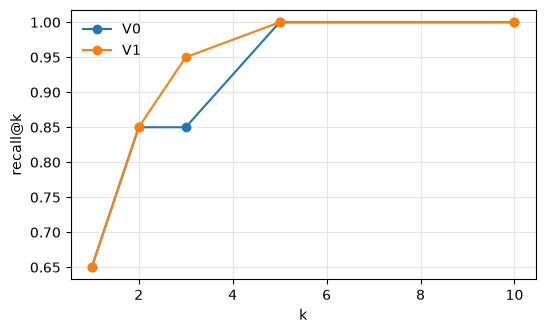

In [18]:
# Calcula el recall@k medio de V0 y V1 para k = 1, 2, 3, 5 y 10 con tu función recall_k y dibuja
# las dos curvas. ¿Con qué k recupera V1 la página correcta en casi todas las preguntas? ¿Y V0?
import matplotlib.pyplot as plt

KS = [1, 2, 3, 5, 10]

def recall_curve(detail):
    pairs = list(zip(detail["recuperadas"], detail["correctas"]))
    if not pairs:
        raise ValueError("No hay preguntas evaluadas para calcular la curva de recall.")
    return [sum(recall_k(retrieved, correct, k) for retrieved, correct in pairs) / len(pairs) for k in KS]

curves = {"V0": recall_curve(d0), "V1": recall_curve(d1)}
fig, ax = plt.subplots(figsize=(6, 3.5))
for name, values in curves.items():
    ax.plot(KS, values, marker="o", label=name)
ax.set_xlabel("k")
ax.set_ylabel("recall@k")
ax.legend(frameon=False)
ax.grid(color="#e4e3df")
plt.show()

In [19]:
from rag_lab import models

models.release()

## Qué hemos visto

- Con verdad de referencia por página, recall@k y MRR@k sirven para cualquier unidad recuperada (fragmento,
  página o figura).
- El judge evalúa por separado fidelidad, relevancia de la respuesta y relevancia del contexto, y debe ser de otra
  familia que el generador.
- Con 20 preguntas hay que mirar el desglose por tipo y desconfiar de las diferencias pequeñas.
- Un judge sin calibrar es una opinión. Cómo medir su acuerdo con una persona está en el anexo A3.

## Ejercicio propuesto

Construye una V1 con el chunking recursivo en lugar del de cabeceras y compara su recall@5 con V0 y V1:

```python
v1r = versions.Dense(versions.pdf_fragments("recursivo"), "recursivo", "V1-recursivo",
                     "Chunking recursivo + denso BGE-M3", "03")
evaluation.evaluate_rag(v1r, questions, register=False)["resumen"]
```

In [21]:
%pip install openai

# Ejercicio propuesto: comparar V0, V1 y V1 con chunking recursivo
v1r = versions.Dense(
    versions.pdf_fragments("recursivo"),
    "recursivo",
    "V1-recursivo",
    "Chunking recursivo + denso BGE-M3",
    "03",
)

eval_v1r = evaluation.evaluate_rag(v1r, questions, register=False)

comparison = pd.DataFrame(
    {
        "version": ["V0", "V1", "V1-recursivo"],
        "recall@5": [
            eval_v0["resumen"]["recall@5"],
            eval_v1["resumen"]["recall@5"],
            eval_v1r["resumen"]["recall@5"],
        ],
        "MRR@10": [
            eval_v0["resumen"]["MRR@10"],
            eval_v1["resumen"]["MRR@10"],
            eval_v1r["resumen"]["MRR@10"],
        ],
    }
).set_index("version")

print("Resumen:")
print(comparison.round(3))

# Opción extra: lista de recall@5 por pregunta para ver si mejora o empeora en algún caso
pairs_v1r = list(zip(eval_v1r["detalle"]["recuperadas"], eval_v1r["detalle"]["correctas"]))
recall5_v1r = [recall_k(r, c, 5) for r, c in pairs_v1r]

print("\nRecall@5 por pregunta (V1-recursivo):")
print(pd.Series(recall5_v1r, index=eval_v1r["detalle"]["id"]).to_dict())

   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---------------------------------- ----- 2.1/2.4 MB 13.2 MB/s eta 0:00:01
   ---------------------------------------- 2.4/2.4 MB 10.4 MB/s  0:00:00

   -------------------- ------------------- 1/2 [openai]
   -------------------- ------------------- 1/2 [openai]
   -------------------- ------------------- 1/2 [openai]
   -------------------- ------------------- 1/2 [openai]
   -------------------- ------------------- 1/2 [openai]
   -------------------- ------------------- 1/2 [openai]
   -------------------- ------------------- 1/2 [openai]
   -------------------- ------------------- 1/2 [openai]
   -------------------- ------------------- 1/2 [openai]
   -------------------- ------------------- 1/2 [openai]
   -------------------- ------------------- 1/2 [openai]
   -------------------- ------------------- 1/2 [openai]
   -------------------- ------------------- 1/2 [openai]
   -------------------- --------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Resumen:
              recall@5  MRR@10
version                       
V0                1.00   0.782
V1                1.00   0.796
V1-recursivo      0.85   0.850

Recall@5 por pregunta (V1-recursivo):
{'q01': 1.0, 'q02': 1.0, 'q03': 1.0, 'q04': 1.0, 'q05': 1.0, 'q06': 1.0, 'q07': 1.0, 'q08': 1.0, 'q09': 1.0, 'q10': 1.0, 'q11': 1.0, 'q12': 1.0, 'q13': 0.0, 'q14': 1.0, 'q15': 0.0, 'q16': 1.0, 'q17': 1.0, 'q18': 1.0, 'q19': 0.0, 'q20': 1.0}
